# Anderson Impurity Model: star and chain geometries

Walkthrough of `AndersonImpurity` -- one impurity orbital coupled to a bath of non-interacting fermions

The notebook also has a simple function to convert between them. 

In [18]:
import warnings 
warnings.filterwarnings("ignore")

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

from qaravan.applications import fermionic_ground_state, fermionic_spectrum, trotter_circuit
from qaravan.core.fermions import FermionicEncoding, majorana_bilinear
from qaravan.core.hamiltonians import AndersonImpurity, bath_interleaved_mode_order
from qaravan.core import display_math
from qaravan.plot import set_style

set_style()
np.set_printoptions(precision=4, suppress=True)

## 1. Star geometry

$H = \varepsilon_d\sum_\sigma d_\sigma^\dagger d_\sigma + U n_{d\uparrow}n_{d\downarrow} + \sum_{k,\sigma}\varepsilon_k c_{k\sigma}^\dagger c_{k\sigma} + \sum_{k,\sigma}(V_k c_{k\sigma}^\dagger d_\sigma + \text{h.c.})$ -- the impurity couples directly to every bath mode, bath modes never couple to each other.

In [20]:
eps_d, U = -0.6, 1.6
eps_bath = [0.9, -0.4, 0.2]
V = [0.5, 0.35, 0.2]

star = AndersonImpurity.star(eps_d=eps_d, U=U, eps_bath=eps_bath, V=V)
print(type(star).__name__)
print(f"topology={star.topology!r}  num_bath={star.num_bath}  num_modes={star.num_fermionic_modes}")
display_math(star, limit=None)

AndersonImpurity
topology='star'  num_bath=3  num_modes=8


<IPython.core.display.Math object>

In [21]:
encoding = FermionicEncoding("jordan_wigner", num_modes=star.num_fermionic_modes)  # identity mode_order
star_ham = star.encode(encoding)
H_star = star_ham.to_matrix()
assert np.allclose(H_star, H_star.conj().T)
print("Hermitian: OK, shape", H_star.shape)

Hermitian: OK, shape (256, 256)


## 2. Chain geometry

$H = H_{\rm imp} + \sum_\sigma\left[V(f_{0,\sigma}^\dagger d_\sigma + \text{h.c.}) + \sum_n\left(\tilde\varepsilon_n f_{n,\sigma}^\dagger f_{n,\sigma} + t_n(f_{n,\sigma}^\dagger f_{n+1,\sigma}+\text{h.c.})\right)\right]$ 

In [22]:
eps_chain = [0.5, -0.3, 0.15]
t_chain = [0.8, 0.6]          # len(eps_chain) - 1
V_chain = 0.7

chain = AndersonImpurity.chain(eps_d=eps_d, U=U, eps_chain=eps_chain, t_chain=t_chain, V=V_chain)
print(f"topology={chain.topology!r}  num_bath={chain.num_bath}  num_modes={chain.num_fermionic_modes}")
print(type(chain).__name__)
display_math(chain, limit=None)

topology='chain'  num_bath=3  num_modes=8
AndersonImpurity


<IPython.core.display.Math object>

In [23]:
chain_encoding = FermionicEncoding("jordan_wigner", num_modes=chain.num_fermionic_modes)
chain_ham = chain.encode(chain_encoding)
H_chain = chain_ham.to_matrix()
assert np.allclose(H_chain, H_chain.conj().T)
print("Hermitian: OK")

Hermitian: OK


## 3. Sanity check: the atomic limit (no bath at all)

With `num_bath=0`, both geometries degenerate to $H_{\rm imp}$ alone -- a clean, closed-form check with no bath machinery involved. The four impurity-only eigenstates ($|0\rangle,\ |\!\uparrow\rangle,\ |\!\downarrow\rangle,\ |\!\uparrow\downarrow\rangle$) have energies $\{0,\ \varepsilon_d,\ \varepsilon_d,\ 2\varepsilon_d+U\}$ exactly.

This can be seen by moving to qubit language where the "computational basis states" ($|00\rangle$, $|01\rangle$, $|10\rangle$, $|11\rangle$) are each an eigenstate of the Hamiltonian since it looks like: $\epsilon_d (n_0+n_1) + Un_0n_1$ where $0,1$ index on the number operators refer to qubit indices. The number operator acting on computational basis gives 0 or 1. 

In [24]:
U = 1.6
eps_d = -0.6
atomic = AndersonImpurity.star(eps_d=eps_d, U=U, eps_bath=[], V=[])
atomic_encoding = FermionicEncoding("jordan_wigner", num_modes=atomic.num_fermionic_modes)

# let's find the 4 eigenstates 
mat = atomic.encode(atomic_encoding).to_matrix()
evals, evecs = np.linalg.eigh(mat)

# turn each evec into Statevector 
from qaravan.backends import Statevector
for i in range(4):
    print(f"eigenvalue {i}: {evals[i]:.4f}")
    display_math(Statevector(array=evecs[:, i]))

eigenvalue 0: -0.6000


<IPython.core.display.Math object>

eigenvalue 1: -0.6000


<IPython.core.display.Math object>

eigenvalue 2: 0.0000


<IPython.core.display.Math object>

eigenvalue 3: 0.4000


<IPython.core.display.Math object>

## 4. A real downfolded material Hamiltonian (5-bath star)

The 5-bath star parameters from Table 1 of the source document ($n_b=5 \Rightarrow 2(n_b+1)=12$ qubits, matching the document's own "12-qubit system" caption -- a nice independent check that the mode-counting convention above is right).

In [25]:
# Table 1, nb=5 row (Ca2CuO2Cl2 downfolded single-band model)
U_mat = 3.232
eps_d_mat = -1.309
eps_bath_mat = [0.735, 1.587, 0.255, 0.065, -0.001]
V_mat = [0.988, 2.432, 1.513, 0.388, 0.155]

star_ham = AndersonImpurity.star(eps_d=eps_d_mat, U=U_mat, eps_bath=eps_bath_mat, V=V_mat)
print(f"num_bath={star_ham.num_bath}, num_modes={star_ham.num_fermionic_modes}")
assert star_ham.num_fermionic_modes == 12

mode_order, annotation = bath_interleaved_mode_order(star_ham.num_bath, annotate=True)
print(annotation)
star_encoding = FermionicEncoding("jordan_wigner", num_modes=star_ham.num_fermionic_modes, mode_order=mode_order)
star_encoding

num_bath=5, num_modes=12
q0=b1↑ q1=b1↓ q2=b2↑ q3=b2↓ q4=b3↑ q5=b3↓ q6=b4↑ q7=b4↓ q8=b5↑ q9=b5↓ q10=i↑ q11=i↓


FermionicEncoding(name='jordan_wigner', num_modes=12, mode_order=(1, 7, 2, 8, 3, 9, 4, 10, 5, 11, 0, 6))

In [26]:
gs = fermionic_ground_state(star_ham, star_encoding, method="naive_lanczos")
print(type(gs).__name__)

Statevector


In [27]:
qubit_ham = star_ham.encode(star_encoding)
E0 = gs.expectation(qubit_ham.as_observable()).real
print(f"ground energy E0 = {E0:.6f}")

ground energy E0 = -5.678950


## 5. Cross-check against the equivalent chain

Star and chain are unrelated parameterizations *unless* the chain parameters are actually
derived from the star ones -- which the source document shows how to do (§2.1, eq. 3-7):
Lanczos-tridiagonalize the diagonal bath-energy operator $\hat\varepsilon={\rm diag}(\varepsilon_k)$,
seeded by the normalized hybridization vector $v_k = V_k/V$, $V=\sqrt{\sum_k V_k^2}$. That
produces exactly the $\tilde\varepsilon_n$, $t_n$ of eq. (7)-(8).

In [28]:
def lanczos_chain_params(eps_bath, V):
    """Notebook-only, ad-hoc star->chain conversion (eq. 3-7): Lanczos-tridiagonalize
    diag(eps_bath) seeded by V/||V||. Returns (eps_chain, t_chain, V_total)."""
    eps_bath = np.asarray(eps_bath, dtype=float)
    V = np.asarray(V, dtype=float)
    num_bath = len(eps_bath)
    V_total = np.sqrt(np.sum(V**2))

    f_curr = V / V_total          # f_0, eq. (3)
    f_prev = np.zeros(num_bath)
    b_prev = 0.0
    eps_chain = np.zeros(num_bath)
    t_chain = np.zeros(num_bath - 1)

    for n in range(num_bath):
        Df = eps_bath * f_curr
        a_n = f_curr @ Df
        eps_chain[n] = a_n
        if n == num_bath - 1:
            break
        r = Df - a_n * f_curr - b_prev * f_prev
        b_n = np.linalg.norm(r)
        t_chain[n] = b_n
        f_prev, f_curr = f_curr, r / b_n
        b_prev = b_n
    return eps_chain, t_chain, V_total


eps_chain_mat, t_chain_mat, V_total_mat = lanczos_chain_params(eps_bath_mat, V_mat)
print("eps_chain:", eps_chain_mat)
print("t_chain:  ", t_chain_mat)
print("V (impurity <-> f_0):", V_total_mat)

eps_chain: [1.1436 0.7299 0.6184 0.1312 0.018 ]
t_chain:   [0.5975 0.2214 0.1914 0.0336]
V (impurity <-> f_0): 3.058513691321325


In [29]:
chain_ham = AndersonImpurity.chain(
    eps_d=eps_d_mat, U=U_mat, eps_chain=eps_chain_mat.tolist(), t_chain=t_chain_mat.tolist(), V=V_total_mat
)
chain_encoding = FermionicEncoding("jordan_wigner", num_modes=chain_ham.num_fermionic_modes)

In [30]:
E0_chain = fermionic_spectrum(chain_ham, chain_encoding, num_eigenvalues=1, method="naive_lanczos")[0]
print(f"star  E0 = {E0:.10f}")
print(f"chain E0 = {E0_chain:.10f}")
assert np.isclose(E0, E0_chain, atol=1e-9)

# Stronger check: spectra agree, not just the ground energy
spec_star = fermionic_spectrum(star_ham, star_encoding, num_eigenvalues=10, method="naive_lanczos")
spec_chain = fermionic_spectrum(chain_ham, chain_encoding, num_eigenvalues=10, method="naive_lanczos")
assert np.allclose(spec_star, spec_chain, atol=1e-9)
print("Lowest 10-eigenvalue spectra agree: the Lanczos-derived chain is exactly the same physics as the star.")

star  E0 = -5.6789498172
chain E0 = -5.6789498172
Lowest 10-eigenvalue spectra agree: the Lanczos-derived chain is exactly the same physics as the star.


## 6. Fixed-particle-number ground state

Reuses `ground_state(fixed_particle_number=...)` from `applications/` -- nothing AIM-specific
was needed for this to work.

In [31]:
n_elec = 6    
gs = fermionic_ground_state(star_ham, star_encoding, fixed_particle_number=n_elec)
print(gs.expectation(qubit_ham.as_observable()).real) 
gs

-5.53051950118714


0.4890|000000111111⟩ + 0.0836|000001101111⟩ + 0.0303|000001111011⟩ + 0.3452|000001111110⟩ - 0.0836|000010011111⟩ - 0.0303|000010110111⟩ - 0.3452|000010111101⟩ + 0.0143|000011001111⟩ + 0.0052|000011011011⟩ + 0.0585|000011011110⟩ + ... (387 more)

## 7. A Majorana observable on the impurity (the Green's function's building block)

In [32]:
# Majorana indices 0,1 are gamma_{d,up}, gamma-bar_{d,up} -- the impurity's up-spin Majorana pair
# (impurity_up is mode 0 under the canonical labeling, regardless of encoding).
impurity_majorana_obs = [majorana_bilinear(0, 1)]
encoded_obs = star_encoding.encode_majorana_terms(impurity_majorana_obs)

gs = fermionic_ground_state(star_ham, star_encoding, method="naive_lanczos", fixed_particle_number=6)
value = gs.expectation(encoded_obs)
print(f"{value:.6f}")
assert abs(value.imag) < 1e-10

0.075301+0.000000j


# 8. Trotter error scaling

At `dt → 0`, the one-step Frobenius error between `U_Trotter(dt)` and `e^{-i H dt}` should scale as:
- `O(dt^2)` for order-1 (first-order Suzuki-Trotter)
- `O(dt^3)` for order-2 (symmetric/second-order)

Both geometries set `trotter_groups`: star gets one layer per bath (every hybridization bond touches the impurity), chain gets even/odd bond layers.

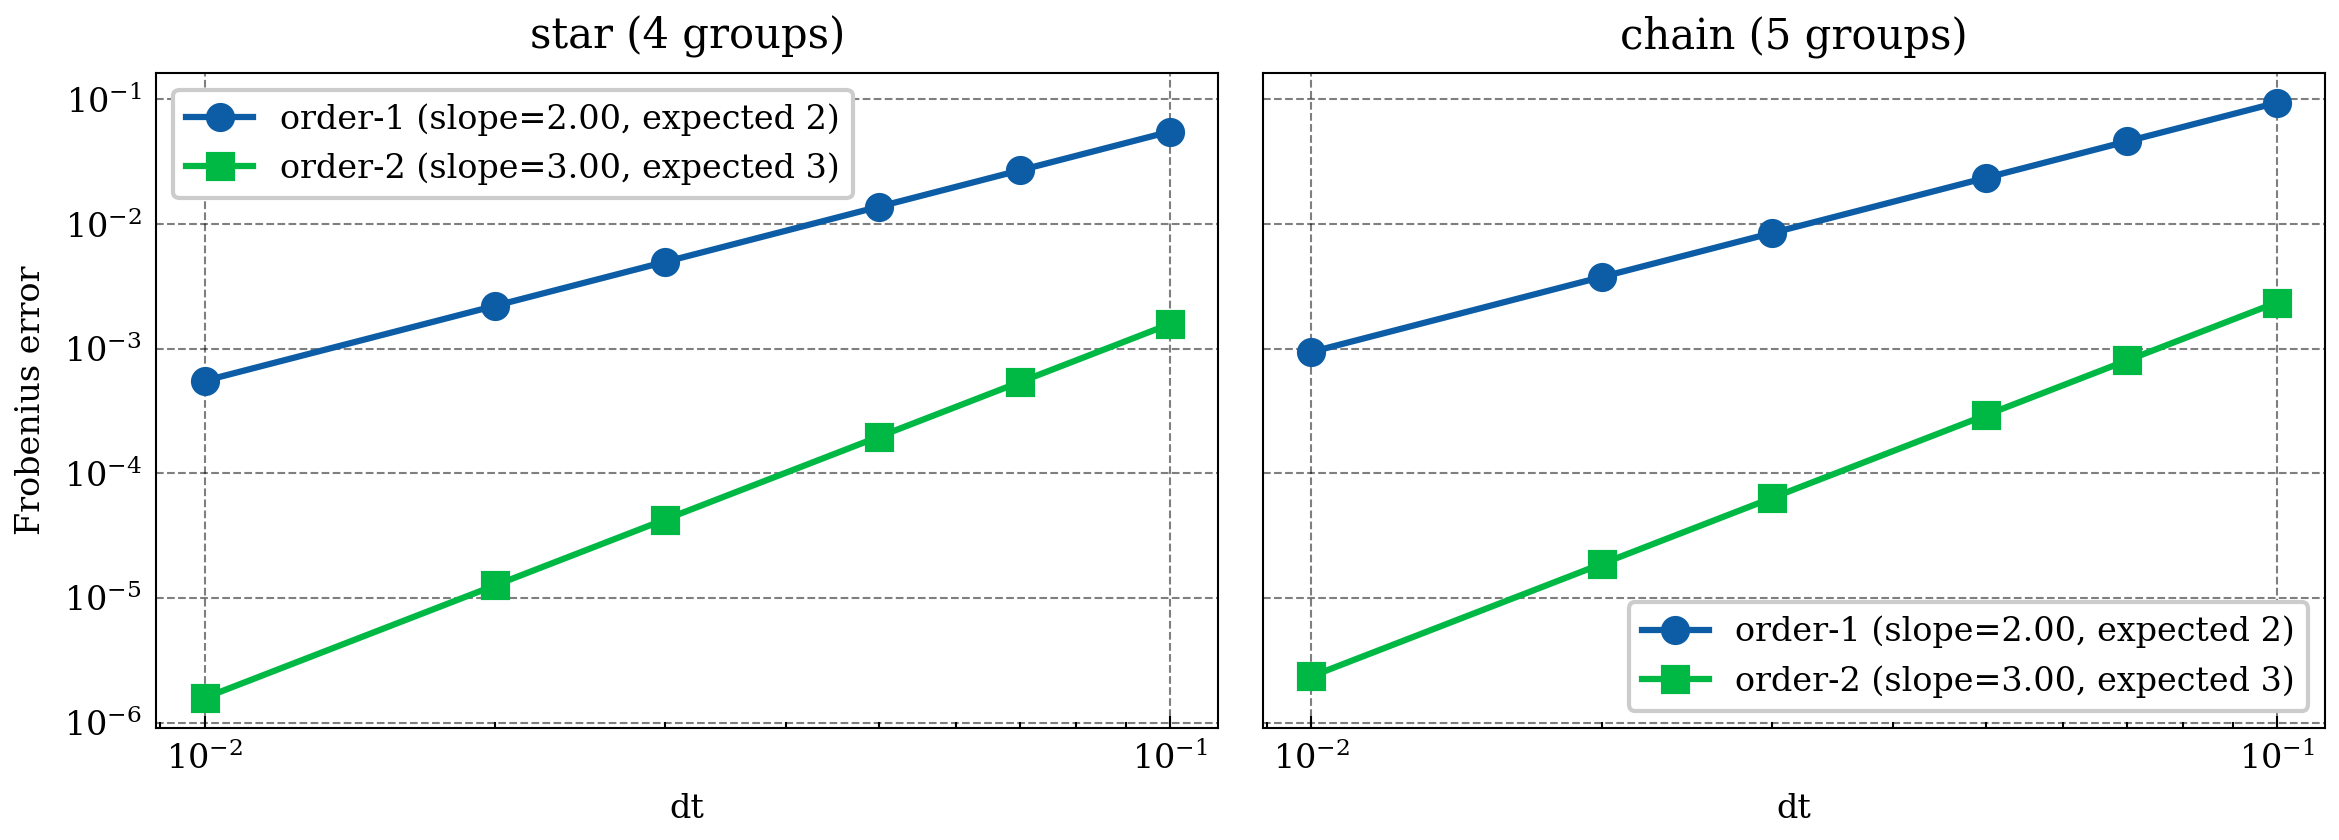

In [33]:
star_qubit_ham = star.encode(FermionicEncoding("jordan_wigner", num_modes=star.num_fermionic_modes))
chain_qubit_ham = chain.encode(FermionicEncoding("jordan_wigner", num_modes=chain.num_fermionic_modes))

dt_values = np.array([0.1, 0.07, 0.05, 0.03, 0.02, 0.01])

fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
for ax, topology, ham in zip(axes, ["star", "chain"], [star_qubit_ham, chain_qubit_ham]):
    H_mat = ham.to_matrix()

    errors_order1, errors_order2 = [], []
    for dt in dt_values:
        exact_prop = expm(-1j * dt * H_mat)
        trotter1 = trotter_circuit(ham, dt, order=1).to_matrix()
        trotter2 = trotter_circuit(ham, dt, order=2).to_matrix()
        errors_order1.append(np.linalg.norm(trotter1 - exact_prop, ord="fro"))
        errors_order2.append(np.linalg.norm(trotter2 - exact_prop, ord="fro"))

    slope1 = np.polyfit(np.log(dt_values), np.log(errors_order1), 1)[0]
    slope2 = np.polyfit(np.log(dt_values), np.log(errors_order2), 1)[0]

    ax.loglog(dt_values, errors_order1, "o-", label=f"order-1 (slope={slope1:.2f}, expected 2)")
    ax.loglog(dt_values, errors_order2, "s-", label=f"order-2 (slope={slope2:.2f}, expected 3)")
    ax.set_xlabel("dt")
    ax.set_title(f"{topology} ({len(ham.trotter_groups)} groups)")
    ax.legend()

axes[0].set_ylabel("Frobenius error")
plt.tight_layout()